# Portfolio Optimization Using SciPy

## Objective

The previous notebook used Monte Carlo simulation to sample many random portfolio allocations. This notebook formulates portfolio construction as constrained numerical optimization using `scipy.optimize.minimize`.

We solve two problems:

1. **Minimum-variance portfolio:** minimize portfolio variance.
2. **Maximum-Sharpe portfolio:** maximize the Sharpe ratio, implemented by minimizing its negative.

The portfolio is long-only and fully invested: weights lie between 0 and 1 and sum to one. We use historical daily returns, so reported return and volatility values are daily estimates. The risk-free rate is assumed to be zero for the Sharpe-ratio illustration.

**Numerical note:** Daily portfolio variances are small numbers. We scale the variance objective inside the optimizer to improve numerical behavior; this does not change the minimizing weights.

## Import Libraries

`scipy.optimize.minimize` solves numerical minimization problems. We provide an objective function, a starting weight vector, and the constraints and bounds that define feasible portfolios.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize

stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]

data = yf.download(
    stocks,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No data was downloaded. Check the tickers, date range, or internet connection.")

close_prices = data["Close"].reindex(columns=stocks).dropna(how="all")
returns = close_prices.pct_change().dropna()

## Expected Returns

The historical average of each stock's daily returns is used as an estimate of expected daily return. Estimates based on historical data are uncertain and can be sensitive to the sample period.

In [2]:
expected_returns = returns[stocks].mean()
expected_returns

,0
Ticker,
RELIANCE.NS,0.000726
TCS.NS,0.000464
INFY.NS,0.000779
HDFCBANK.NS,0.000463
ICICIBANK.NS,0.000816


## Covariance Matrix

The covariance matrix describes the variances of individual daily returns and the covariances between pairs of stocks. We explicitly order its rows and columns to match the ticker list and weight vector.

In [3]:
cov_matrix = returns[stocks].cov()
cov_matrix

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Ticker,,,,,
RELIANCE.NS,0.000317,0.000101,0.000107,0.000127,0.000144
TCS.NS,0.000101,0.000224,0.000184,0.000073,0.000090
INFY.NS,0.000107,0.000184,0.000298,0.000096,0.000118
HDFCBANK.NS,0.000127,0.000073,0.000096,0.000262,0.000192
ICICIBANK.NS,0.000144,0.000090,0.000118,0.000192,0.000350


## Why Optimization?

Monte Carlo simulation evaluates a finite random sample of possible allocations, so it may miss the best feasible portfolio. Numerical optimization instead searches for weights that minimize a chosen objective while respecting constraints.

The optimizer does not know what a “good” portfolio means until we define an objective function. Here we minimize variance for one solution and maximize the Sharpe ratio for another.

## Portfolio Constraints

A fully invested portfolio satisfies the budget constraint

$$
\sum_{i=1}^{n} w_i = 1.
$$

A long-only portfolio without short selling satisfies

$$
0 \leq w_i \leq 1 \quad \text{for every asset } i.
$$

The equality constraint ensures that all weights sum to 100%; the bounds prohibit negative allocations and prevent any single weight from exceeding 100%. These assumptions can be relaxed in more advanced models.

### Portfolio Return Function

The function below maps a candidate weight vector to its estimated expected daily portfolio return. SciPy will pass different candidate weight vectors to the function during optimization.

In [4]:
def portfolio_return(weights):
    return float(np.dot(weights, expected_returns.to_numpy()))

### Portfolio Variance Function

Portfolio variance is \(w^T\Sigma w\). The function returns a single scalar for any candidate weight vector. The covariance matrix is converted to a NumPy array so that matrix multiplication is explicit and its order matches the weights.

In [5]:
def portfolio_variance(weights):
    sigma = cov_matrix.to_numpy()
    return float(weights.T @ sigma @ weights)

### Portfolio Volatility Function

Volatility is the square root of variance. This function reuses `portfolio_variance` rather than duplicating the formula.

In [6]:
def portfolio_volatility(weights):
    return float(np.sqrt(max(portfolio_variance(weights), 0.0)))

### Negative Sharpe Ratio Function

The Sharpe ratio is excess expected return divided by volatility. Since `minimize()` minimizes rather than maximizes, we return the negative Sharpe ratio. Minimizing a negative value is equivalent to maximizing the original positive value.

For simplicity, the daily risk-free rate is set to zero here.

In [7]:
risk_free_rate_daily = 0.0

def negative_sharpe_ratio(weights):
    volatility = portfolio_volatility(weights)
    if volatility <= 0:
        return np.inf
    return -(portfolio_return(weights) - risk_free_rate_daily) / volatility

The negative sign is essential: the optimizer minimizes the function it receives. A portfolio with Sharpe ratio 0.8 has negative Sharpe -0.8, which is a smaller objective value than -0.5, so minimizing negative Sharpe favors the larger original Sharpe ratio.

### Budget Constraint

SciPy's SLSQP interface expects an equality constraint function that evaluates to zero when the constraint is satisfied. The function below returns the sum of weights minus one.

In [8]:
constraints = ({
    "type": "eq",
    "fun": lambda weights: np.sum(weights) - 1
})

### Bounds

Each weight is constrained to the interval [0, 1]. `bounds` contains one `(lower, upper)` pair for every stock, in the same order as `stocks`.

In [9]:
bounds = tuple((0.0, 1.0) for _ in stocks)

### Initial Guess

Optimization needs a starting point. We use the equal-weight portfolio, but this is only the starting guess and is not forced to be the final solution.

In [10]:
initial_weights = np.full(len(stocks), 1 / len(stocks))
pd.Series(initial_weights, index=stocks, name="Initial Weight")

,Initial Weight
RELIANCE.NS,0.2
TCS.NS,0.2
INFY.NS,0.2
HDFCBANK.NS,0.2
ICICIBANK.NS,0.2


## Minimum-Variance Optimization

The optimizer minimizes portfolio variance subject to the budget constraint and long-only bounds. We multiply the objective by 10,000 to improve numerical scaling because daily variances are small. This positive scaling changes the objective's numerical magnitude but not the weights that minimize it.

`SLSQP` is a numerical algorithm that supports bounds and equality constraints. Always inspect `success` and `message`; a returned vector alone does not prove the optimizer succeeded.

In [11]:
variance_scale = 10_000

min_variance = minimize(
    lambda weights: variance_scale * portfolio_variance(weights),
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000, "disp": True}
)

print("Success:", min_variance.success)
print("Message:", min_variance.message)
print("Iterations:", min_variance.nit)

Optimization terminated successfully    (Exit mode 0)
            Current function value: 1.4755527436857545
            Iterations: 7
            Function evaluations: 46
            Gradient evaluations: 7
Success: True
Message: Optimization terminated successfully
Iterations: 7


In [12]:
min_variance_weights = pd.Series(min_variance.x, index=stocks, name="Minimum-Variance Weight")
min_variance_weights

,Minimum-Variance Weight
RELIANCE.NS,0.164142
TCS.NS,0.411605
INFY.NS,0.060240
HDFCBANK.NS,0.301825
ICICIBANK.NS,0.062188


In [13]:
min_variance.success

True

In [14]:
print(f"Minimum daily variance: {portfolio_variance(min_variance.x):.10f}")
print(f"Minimum daily volatility: {portfolio_volatility(min_variance.x):.6f} ({portfolio_volatility(min_variance.x):.2%})")

Minimum daily variance: 0.0001475553
Minimum daily volatility: 0.012147 (1.21%)


In [15]:
min_variance

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 1.4755527436857545
           x: [ 1.641e-01  4.116e-01  6.024e-02  3.018e-01  6.219e-02]
         nit: 7
         jac: [ 2.951e+00  2.951e+00  2.951e+00  2.951e+00  2.951e+00]
        nfev: 46
        njev: 7
 multipliers: [ 2.951e+00]

In [16]:
portfolio_variance(initial_weights)

0.00015664689237813298

In [17]:
portfolio_variance(min_variance.x)

0.00014755527436857545

## Maximum-Sharpe Optimization

We now minimize the negative Sharpe ratio subject to the same bounds and budget constraint. This produces the maximum-Sharpe solution found by the numerical optimizer under the chosen model and assumptions.

In [18]:
max_sharpe = minimize(
    negative_sharpe_ratio,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000, "disp": True}
)

print("Success:", max_sharpe.success)
print("Message:", max_sharpe.message)
print("Iterations:", max_sharpe.nit)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -0.0565543905826682
            Iterations: 12
            Function evaluations: 72
            Gradient evaluations: 12
Success: True
Message: Optimization terminated successfully
Iterations: 12


## Maximum-Sharpe Weights

The `.x` attribute stores the optimizer's solution vector. The ticker labels are attached here so that each weight can be interpreted correctly.

In [19]:
max_sharpe_weights = pd.Series(max_sharpe.x, index=stocks, name="Maximum-Sharpe Weight")
max_sharpe_weights

,Maximum-Sharpe Weight
RELIANCE.NS,2.738400e-01
TCS.NS,0.000000e+00
INFY.NS,4.114491e-01
HDFCBANK.NS,1.706941e-17
ICICIBANK.NS,3.147109e-01


## Compare Portfolio Statistics

The equal-weight portfolio is a baseline. The two optimized portfolios use different objectives, so they need not have the same allocation or risk-return profile. All figures below are daily estimates; the Sharpe ratio uses a zero daily risk-free rate.

In [20]:
def portfolio_statistics(weights):
    ret = portfolio_return(weights)
    vol = portfolio_volatility(weights)
    sharpe = (ret - risk_free_rate_daily) / vol if vol > 0 else np.nan
    return ret, vol, sharpe

portfolio_definitions = {
    "Equal Weight": initial_weights,
    "Minimum Variance (SciPy)": min_variance.x,
    "Maximum Sharpe (SciPy)": max_sharpe.x
}

comparison_rows = {}
for name, weights in portfolio_definitions.items():
    ret, vol, sharpe = portfolio_statistics(weights)
    comparison_rows[name] = {
        "Expected Daily Return": ret,
        "Daily Volatility": vol,
        "Daily Sharpe Ratio": sharpe
    }

comparison = pd.DataFrame.from_dict(comparison_rows, orient="index")
comparison

,Expected Daily Return,Daily Volatility,Daily Sharpe Ratio
Equal Weight,0.000650,0.012516,0.051908
Minimum Variance (SciPy),0.000548,0.012147,0.045079
Maximum Sharpe (SciPy),0.000776,0.013727,0.056554


## Compare Asset Allocations

This table shows the percentage of capital allocated to each stock under the three portfolio choices.

In [21]:
allocation_comparison = pd.DataFrame({
    name: weights for name, weights in portfolio_definitions.items()
}, index=stocks)
(allocation_comparison * 100).round(2).rename_axis("Ticker").rename(columns=lambda name: f"{name} (%)")

,Equal Weight (%),Minimum Variance (SciPy) (%),Maximum Sharpe (SciPy) (%)
Ticker,,,
RELIANCE.NS,20.0,16.41,27.38
TCS.NS,20.0,41.16,0.00
INFY.NS,20.0,6.02,41.14
HDFCBANK.NS,20.0,30.18,0.00
ICICIBANK.NS,20.0,6.22,31.47


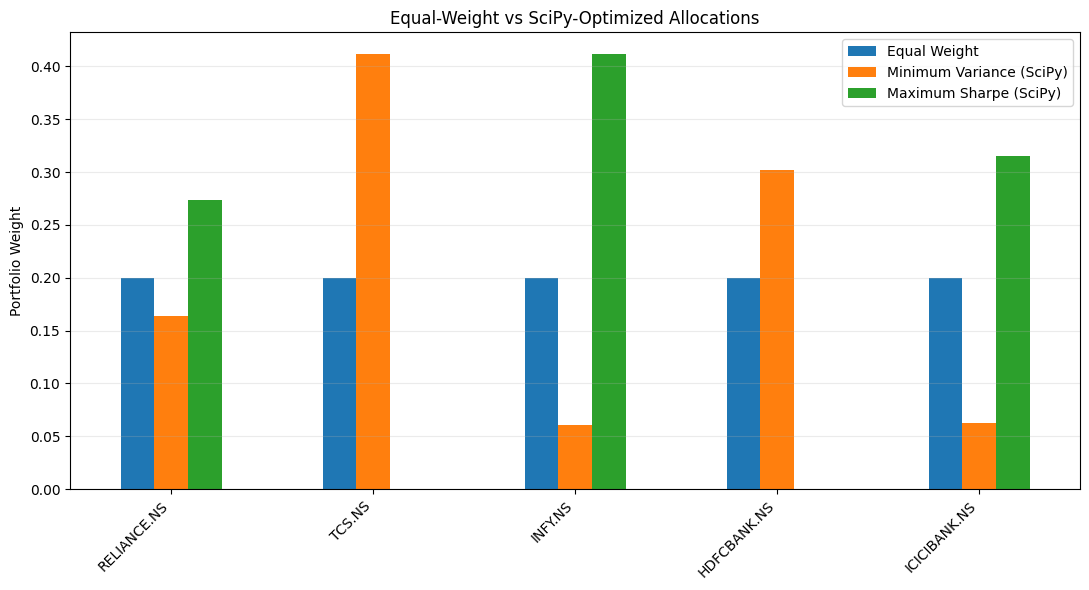

In [22]:
allocation_comparison.plot(kind="bar", figsize=(11, 6))
plt.ylabel("Portfolio Weight")
plt.title("Equal-Weight vs SciPy-Optimized Allocations")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Conclusions

- Constrained numerical optimization finds portfolio weights for a specified objective, subject to the assumptions and constraints provided.
- The minimum-variance portfolio minimizes estimated portfolio variance; the maximum-Sharpe portfolio maximizes estimated excess return per unit of volatility.
- The optimizer's `success` flag and message should always be checked before interpreting the result.
- Aligning ticker order across weights, mean returns, and covariance matrices is essential for valid calculations.
- Results depend on historical estimates and the selected sample. They are not guaranteed to outperform in the future.

The analysis excludes transaction costs, taxes, slippage, and estimation uncertainty. A next step is to compare the optimized portfolios with a benchmark and evaluate them out of sample.